# Tutorial: **δHBV 1.1p**

---

This notebook demonstrates training and forward simulation with the δHBV 1.1p model developed by [Yalan Song et al. (2025)](https://doi.org/10.22541/essoar.172304428.82707157/v2). A pre-trained model is provided for those who only wish to run the model forward.

For explanation of model structure, methodologies, data, and performance metrics, please refer to Song's publication [below](#publication). If you find this code is useful in your own work, please include the aforementioned citation.

**Note**: If you are new to the dMG framework, we suggest first looking at our [δHBV 1.0 tutorial](./../hydrology/example_dhbv.ipynb).

<br>

### Before Running:
- **Environment**: See [setup.md](./../../docs/setup.md) for ENV setup. dMG must be installed with dependencies + hydrodl2 to run this notebook.

- **Model**: Download pretrained δHBV 1.1p model weights from [AWS](https://mhpi-spatial.s3.us-east-2.amazonaws.com/mhpi-release/models/dhbv_1_1p_trained.zip). Then update the model config:

    - In [`./generic_deltamodel/example/conf/config_dhbv_1_1p.yaml`](./../conf/config_dhbv_1_1p.yaml), update *trained_model* with your path to the parent directory containing both trained model weights `dhbv_1_1p_ep50.pt` (or *Ep100*) **and** normalization file `normalization_statistics.json`.
    - **Note**: make sure this path includes the last closing forward slash: e.g., `./your/path/to/model/`.

- **Data**: Download the CAMELS data extraction from [AWS](https://mhpi-spatial.s3.us-east-2.amazonaws.com/mhpi-release/camels/camels_data.zip). Then, updated the data configs:

    - In [`./generic_deltamodel/example/conf/observations/camels_531.yaml`](./../conf/observations/camels_531.yaml) and [`camels_671.yaml`](./../conf/observations/camels_671.yaml), update...
        1. *data_path* with `camels_dataset` path,
        2. *gage_info* with `gage_ids.npy` path,
        3. *subset_path* with `531_subset.txt` path (camels_531 only).

    - The full 671-basin or 531-basin CAMELS datasets can be selected by setting `observations: camels_671` or `camels_531` in the model config, respectively.

- **Hardware**: The NNs used in this model require CUDA support only available with Nvidia GPUs. For those without access, T4 GPUs can be used when running this notebook with dMG on [Google Colab](https://colab.research.google.com/).

<br>

### Publication:

*Yalan Song, Kamlesh Sawadekar, Jonathan M Frame, Ming Pan, Martyn Clark, Wouter J M Knoben, Andrew W Wood, Trupesh Patel, Chaopeng Shen. "Physics-informed, Differentiable Hydrologic  Models for Capturing Unseen Extreme Events." ESS Open Archive (2025). https://doi.org/10.22541/essoar.172304428.82707157/v2.*

<br>

### Issues:
For questions, concerns, bugs, etc., please reach out by posting an [issue](https://github.com/mhpi/generic_deltamodel/issues).

---


## 1. Forward δHBV 1.1p Simulation Mode (no output metrics saved)

After completing training or you have pretrianed models saved, forward δHBV 1.1p with the code block below.

Note:
- The settings defined in the config `./generic_deltamodel/example/conf/config_dhbv_1_1p.yaml` are set to replicate benchmark performance on 531 CAMELS basins.
- The first year (`warm_up` in the config, default is 365 days) of the inference period is used for initializing HBV's internal states (water storages) and is, therefore, excluded from the model's prediction output.

### 1.1 Simulation Settings Demonstration

In [1]:
import sys
sys.path.append('../../') 
from src.dmg import ModelHandler 
from src.dmg.core.utils import import_data_loader, print_config, print_dataset_info, set_randomseed
from tempfunctions import *
from example import load_config 
#------------------------------------------#
# Define model settings here.
from tempfunctions import get_config_path

MODEL_TYPE = "d3"   # change only this: "d3", "d2", or "static"
CONFIG_PATH = get_config_path(MODEL_TYPE)
#------------------------------------------#

# 1. Load configuration dictionary of model parameters and options.
config = load_config(CONFIG_PATH)
config['mode'] = 'sim'

print_config(config)
# print("Config Keys:", config.keys())
# print("config['multimodel_type']", config['multimodel_type'])
# Set random seed for reproducibility.
set_randomseed(config['seed'])

# 2. Initialize the differentiable HBV 1.1p model (LSTM + HBV 1.1p).
model = ModelHandler(config, verbose=True) # model key is ['Hbv_1_1p'] 
nn_model = model.model_dict["Hbv_1_1p"].nn_model

# 3. Load and initialize a dataset dictionary of NN and HBV model inputs.
data_loader_cls = import_data_loader(config['data_loader'])
data_loader = data_loader_cls(config, test_split=False, overwrite=False)
print_dataset_info(data_loader.dataset)    


Current Configuration
  Experiment Mode:    sim                 
  Model 1:            Hbv_1_1p            
  Dynamic Params:     ['parBETA', 'parK0', 'parBETAET']

Data Loader
  Data Source:        camels_531          
  Simulation Range :  2009/10/01          2012/09/30          

Experiment Parameters
  Train Epochs:       100                 Batch Size:         100                 
  Start Epoch:        0                   Save Epoch:         5                   
  Loss Fn:            NseBatchLoss        
  Optimizer:          Adadelta            LR Scheduler:       None                

Machine
  Device:             cuda:0              
  Dtype:              torch.float32       


Dataset Inputs
Dataset key    Shape               Description
------------------------------------------------------------
x_phy          (1096, 531, 3)       # [time, basin, forcing_features]
c_phy          (531, 0)             # [basin, attr_features] (no physical attributes here)
x_nn           (1096

In [2]:
import numpy as np
import json
# # Gage settings
gage_ids = np.load(config["observations"]["gage_info"], allow_pickle=True)
subset_file = config["observations"]["subset_path"]
GAGE_NAME_PATH = "./predownloaded/camels_name.txt"

with open(subset_file, "r") as f:
    content = f.read().strip()
gage_ids_subset = json.loads(content) if content.startswith("[") else np.loadtxt(subset_file, dtype=int).tolist()  

# 1. Predictions and timesteps
GAGE_ID = 9035900 # 2350900 

if config['observations']['name'] == 'camels_671':
    basin_idx = list(gage_ids).index(GAGE_ID) if GAGE_ID in gage_ids else None
    basin_pool = list(gage_ids)
elif config['observations']['name'] == 'camels_531':
    basin_idx = list(gage_ids_subset).index(GAGE_ID) if GAGE_ID in gage_ids_subset else None
    basin_pool = list(gage_ids_subset)

### 1.2 Simulation with Daymet Forcings Only

In [3]:
wantorun = False # set to true if you want the simulation result with only daymet forcings

import pandas as pd
import torch
from tempfunctions import *
from src.dmg.core.post import plot_hydrograph
from src.dmg.core.utils import Dates
if wantorun:
    output = model(
        data_loader.dataset,
        eval=True,
    )

    # prediction can be numpy
    pred = output['Hbv_1_1p']['streamflow']
    timesteps = Dates(config['sim'], config['model']['rho']).batch_daily_time_range
    warm_up = config['model']['phy']['warm_up']
    timesteps = timesteps[warm_up:]
    streamflow_pred_basin = pred[:, basin_idx].squeeze()
    if torch.is_tensor(streamflow_pred_basin):
        streamflow_pred_basin = streamflow_pred_basin.detach().cpu().numpy()

    # keep obs as torch tensor so plot_hydrograph does not zero it out 
    obs_basin = data_loader.dataset["target"][:, basin_idx].squeeze()
    if not torch.is_tensor(obs_basin):
        obs_basin = torch.as_tensor(obs_basin)

    # 2. Plot
    RESAMPLE = 'D'
    obs_basin = obs_basin[warm_up:]
    gage_name = obtain_gage_name(GAGE_NAME_PATH, GAGE_ID)

    plot_hydrograph(
        timesteps,
        streamflow_pred_basin,
        obs=obs_basin,
        resample=RESAMPLE,
        title=f"Hydrograph for Gage ID {GAGE_ID} ({gage_name})",
        ylabel='Streamflow (mm/day)',
    ) 

### 1.3 GEFS Simulation with warm start


=== Running forecast for basin 1073000 ===
save start
save for simulation
save stop
last sim_pre_GEFS value: 0.17513649
first Q_next value: 0.16374788
end here
end here
end here
end here
end here
path is ../example/conf/config_dhbv_1_1p_3dyn.yaml

Dataset Inputs
Dataset key    Shape               Description
------------------------------------------------------------
x_phy          (1096, 531, 3)       # [time, basin, forcing_features]
c_phy          (531, 0)             # [basin, attr_features] (no physical attributes here)
x_nn           (1096, 531, 3)       # [time, basin, nn_forcing_features]
c_nn           (531, 35)            # [basin, nn_attr_features]
xc_nn_norm     (1096, 531, 38)      # [time, basin, combined_features]
target         (1096, 531, 1)       # [time, basin, 1] observed streamflow

Sample of target tensor (first 5 timesteps, first basin):
tensor([1.0365, 0.8744, 0.7507, 2.0175, 2.3928], device='cuda:0')
Difference between continuous first forecast value and rest

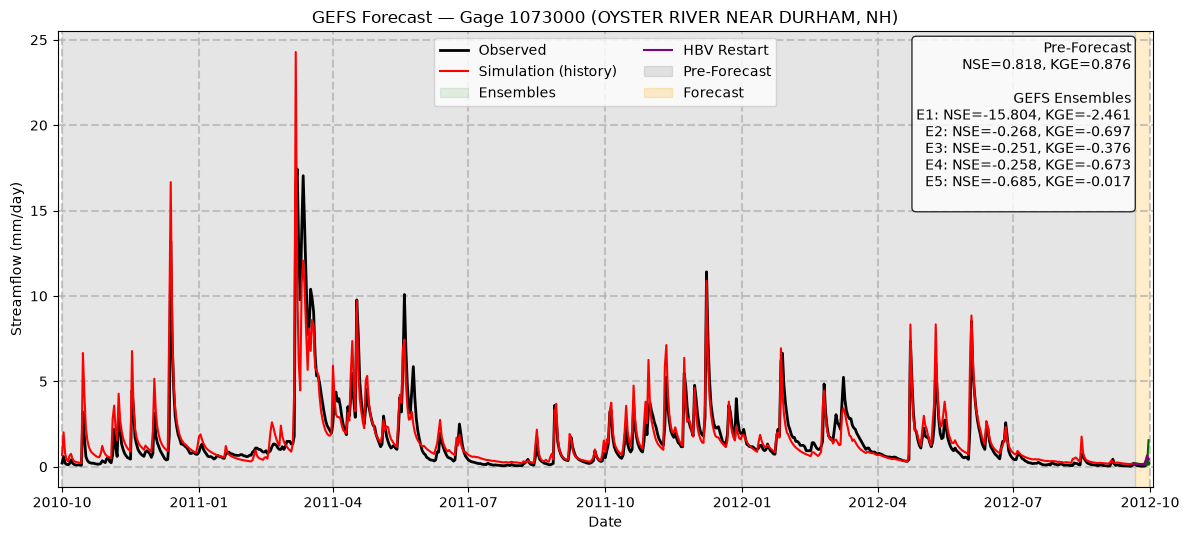

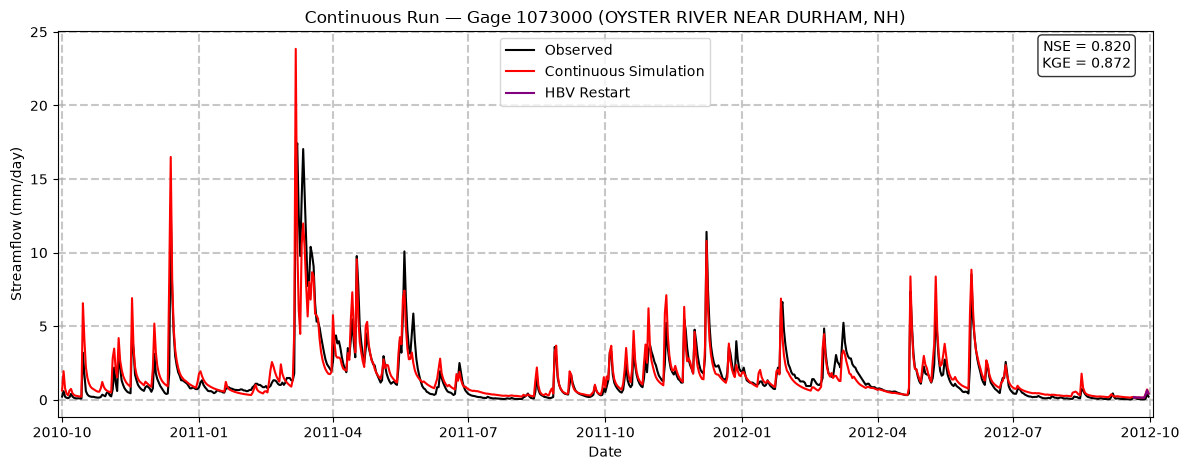

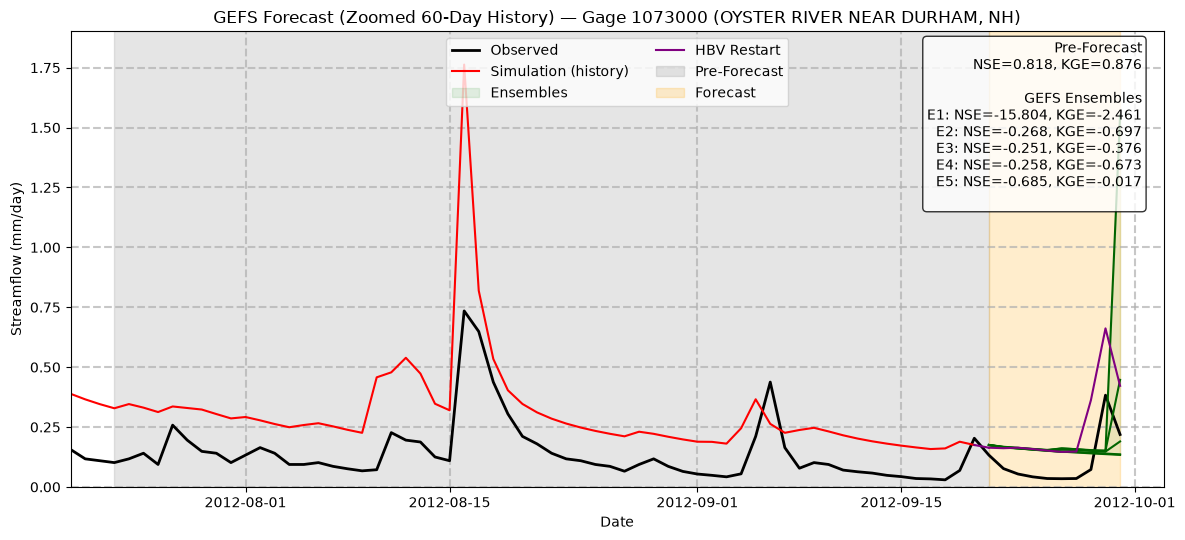

Saved plot for basin 1073000 → ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/plots/3GEFS/GEFS_1073000


In [4]:
import os
import numpy as np
import pandas as pd
import torch 
from src.dmg.core.utils import Dates  
import importlib
import tempfunctions
importlib.reload(tempfunctions)
from tempfunctions import *

# ---------------- Path settings ---------------- #

GEFS_DIR       = "/beegfs/sets/aw-ciroh/common/met_fcsts/gefs_v12/camels_gII/camels671/zn_processed_hcst"
#GEFS_DIR      ="/u/st/dr/awwood/aw-ciroh-proj/projects/dl_da/daymet-gefs-camels-gII"
STATE_PATH     = f"{config['sim_dir']}simulation_gefs/save_states_restart/model_states.pt" # where the stopped states are saved:nn+hbv

# ---------------- Simulation settings ---------------- #
PRED_DATE      = pd.to_datetime("2012-09-21")
FORECAST       = 10
N_ENSEMBLES    = 5
WARMUP         = 365  # this is to change it differ from the config warmup, if you want to, otherwise it is the same
device         = torch.device("cuda" if torch.cuda.is_available() else "cpu") 

# ---------------- Post/Pre-processing settings ---------------- #
WINDOW         = 30 # pre-processing on correcting window (in days)
PRE            = 'scalar'  # or 'cdf'
POST           = True
 
# ---------------- Basin(s) selection ---------------- #
# selected_basins = [
selected_basins = selectbasins()  # [9035900] # 7362100, 2350900 
selected_basins = selected_basins[:1]
sidx, eidx, timesteps, history_len = startid_endid(config, WARMUP, PRED_DATE, FORECAST)

# ---------------- Loop over selected basins ---------------- #
for GAGE_ID in selected_basins:
    print(f"\n=== Running forecast for basin {GAGE_ID} ===")
    basin_idx = basin_pool.index(GAGE_ID) 
    name = list(model.model_dict.keys())[0]
     
    # ----------- Run then stop at sidx------------- #  
    ###################################################### 
    sim_pre_GEFS = run_segment(# 716 
        model=model,
        dataset=data_loader.dataset,
        basin_idx=basin_idx,
        device=device,
        name=name,
        start_idx=None,
        end_idx=sidx,
        warm_up=WARMUP,
        cache_states=True,
        warm_up_states=True,
    )
    # save states to external file
    model.verbose = False    
    print("save start")
    model.save_states() # nn: <class 'tuple'>, phy:tuple of 5 torch.Size([1, 16]) --> 5*[1, 16],  (sp, mw, sm, suz, slz) 
    ######################################################
    print("save stop")
    
    # ---------------- Restart rest (keep daymet forcings) ---------------- # 
    ######################################################
    Q_next = run_segment(
        model=model,
        dataset=data_loader.dataset,
        basin_idx=basin_idx,
        device=device,
        name=name,
        start_idx=sidx,
        end_idx=None,
        warm_up=0,
        cache_states=True,
        warm_up_states=True,
        state_path=STATE_PATH,
    )
    print("last sim_pre_GEFS value:", sim_pre_GEFS[-1])
    print("first Q_next value:", Q_next[0])
    ######################################################
      
    
    # ---------------- Restart rest (using GEFS forcings) ---------------- #
    ######################################################
    ens_preds = run_warm_forecasts_restart( 
        model=model,
        data_loader=data_loader,
        state_path=STATE_PATH,
        gage_id=GAGE_ID,
        basin_idx=basin_idx,
        start_date=PRED_DATE,
        horizon=FORECAST,
        N_ENSEMBLES=N_ENSEMBLES,
        GEFS_DIR=GEFS_DIR,
        timesteps=timesteps,
        WINDOW=WINDOW,
        CORRECTION=PRE,
        device=device,
        verbose=model.verbose,
    )
    
    if POST:
        ens_preds = post_processing(sim_pre_GEFS, ens_preds) # post-processing
    ######################################################
    
    
    # ---------------- Continuous Simulation ---------------- #
    ######################################################
    # 1. RE-Load a model  
    print("path is", CONFIG_PATH)
    config = load_config(CONFIG_PATH)
    config['mode'] = 'sim'
    set_randomseed(config['seed'])
    model = ModelHandler(config, verbose=True) # model key is ['Hbv_1_1p'] 
    nn_model = model.model_dict["Hbv_1_1p"].nn_model

    # 2. Load and initialize a dataset dictionary of NN and HBV model inputs.
    data_loader_cls = import_data_loader(config['data_loader'])
    data_loader = data_loader_cls(config, test_split=False, overwrite=False)
    print_dataset_info(data_loader.dataset)  
    full_dict = {
        "xc_nn_norm":data_loader.dataset["xc_nn_norm"][:, basin_idx:basin_idx+1, :].clone(),  
        "x_phy":data_loader.dataset["x_phy"][:, basin_idx:basin_idx+1, :].clone()
    } 

    # 3. Run a continues run without restart 
    Q_all_np = run_segment( #(731,)
        model=model,
        dataset=data_loader.dataset,
        basin_idx=basin_idx,
        device=device,
        name=name,
        start_idx=None,
        end_idx=None,
        warm_up=WARMUP,
        cache_states=False,
        warm_up_states=True,
    ) 
    Qf_cont  = Q_all_np[sidx - WARMUP:sidx - WARMUP + FORECAST]  # 15  
    print("Difference between continuous first forecast value and restart first forecast value:", Q_next[0] - Qf_cont[0])
    ###################################################################
    
    
    # ---------------- Plotting ---------------- # 
    # create a figure save path 
    save_dir = os.path.join(f"{config['plot_dir']}", f"3GEFS/GEFS_{GAGE_ID}")

    # double-check the respective dismension that will be displayed
    assert len(sim_pre_GEFS) == history_len, \
        f"Expected history_len={history_len}, but got len(sim_pre_GEFS)={len(sim_pre_GEFS)}"
    
    assert len(Q_all_np) + WARMUP - FORECAST == sidx, (
        f"[INDEX MISMATCH ERROR]\n"
        f"len(Q_all_np)={len(Q_all_np)}, WARMUP={WARMUP}, FORECAST={FORECAST}\n"
        f"Computed: {len(Q_all_np)} + {WARMUP} - {FORECAST} = {len(Q_all_np) + WARMUP - FORECAST}\n"
        f"Expected SIDX={sidx}"
    )
    
    # plot
    plot_forecast_separate(
        GAGE_NAME_PATH=GAGE_NAME_PATH,
        gage_id=GAGE_ID,
        start_date=PRED_DATE,
        obs=data_loader.dataset["target"][sidx - history_len : eidx, basin_idx, 0].detach().cpu().numpy(),
        sim=sim_pre_GEFS,
        ens_preds=ens_preds,
        history_len=history_len,
        Q_all_np=Q_all_np,
        sidx=sidx,
        FORECAST=FORECAST,
        WARMUPTIME=WARMUP,
        det_pred=Q_next,
        save_dir=save_dir,
        file_prefix=f"GEFS_{GAGE_ID}_{PRE}_w{WINDOW}_p{POST}",
    )

In [5]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from matplotlib.backends.backend_pdf import PdfPages

from plot_basin_diagnostics import (
    plot_basin_page,
    load_names,
)

# ============================================================
# 1. SETTINGS
# ============================================================

WARMUP = 365

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

calibration_name = "HBV11p_calibration_A"

# selected_basins = selectbasins()
selected_basins = list(basin_pool)
name = list(model.model_dict.keys())[0]

save_dir = os.path.join(
    config["plot_dir"],
    "calibration_diagnostics",
    calibration_name
)
os.makedirs(save_dir, exist_ok=True)

basin_names = load_names(GAGE_NAME_PATH)

print("Calibration:", calibration_name)
print("Model:", name)
print("Number of basins:", len(selected_basins))
print("Device:", device)
print("Simulation time:", config["sim_time"])


# ============================================================
# 2. CALCULATE METRICS
# ============================================================

def calculate_metrics(obs, sim):

    obs = np.asarray(obs).reshape(-1)
    sim = np.asarray(sim).reshape(-1)

    valid = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[valid]
    sim = sim[valid]

    empty = {
        "KGE": np.nan,
        "NSE": np.nan,
        "r": np.nan,
        "alpha": np.nan,
        "Bias": np.nan,
    }

    if len(obs) < 2:
        return empty

    obs_mean = np.mean(obs)
    sim_mean = np.mean(sim)

    obs_std = np.std(obs)
    sim_std = np.std(sim)

    if obs_std == 0 or obs_mean == 0:
        return empty

    r = pearsonr(obs, sim).statistic

    alpha = sim_std / obs_std
    beta = sim_mean / obs_mean

    kge = 1 - np.sqrt(
        (r - 1)**2 +
        (alpha - 1)**2 +
        (beta - 1)**2
    )

    nse = 1 - (
        np.sum((obs - sim)**2) /
        np.sum((obs - obs_mean)**2)
    )

    bias = 100 * np.sum(sim - obs) / np.sum(obs)

    return {
        "KGE": float(kge),
        "NSE": float(nse),
        "r": float(r),
        "alpha": float(alpha),
        "Bias": float(bias),
    }


# ============================================================
# 3. CONSTRUCT SIMULATION DATES
# ============================================================

def get_simulation_dates(config, n_timesteps):
    """
    Construct daily dates from config['sim_time'].

    Supports:
      ['YYYY-MM-DD', 'YYYY-MM-DD']
      {'start': ..., 'end': ...}
      {'start_date': ..., 'end_date': ...}

    Assumes the first target timestep corresponds to
    the simulation start date.
    """

    sim_time = config["sim_time"]

    if isinstance(sim_time, (list, tuple)):
        start = sim_time[0]

    elif isinstance(sim_time, dict):
        start = None

        for key in [
            "start",
            "start_date",
            "start_time",
            "begin",
        ]:
            if key in sim_time:
                start = sim_time[key]
                break

        if start is None:
            raise ValueError(
                f"Unknown sim_time dictionary format: {sim_time}"
            )

    elif isinstance(sim_time, (str, pd.Timestamp)):
        start = sim_time

    else:
        raise ValueError(
            f"Unsupported sim_time format: {sim_time}"
        )

    start = pd.to_datetime(start)

    dates = pd.date_range(
        start=start,
        periods=n_timesteps,
        freq="D"
    )

    return dates


n_timesteps = data_loader.dataset["target"].shape[0]

dates_all = get_simulation_dates(
    config,
    n_timesteps
)

print("\nDate alignment:")
print("First dataset date:", dates_all[0])
print("Last dataset date:", dates_all[-1])
print("Total timesteps:", len(dates_all))
print("Warmup days:", WARMUP)
print("Expected evaluation days:", n_timesteps - WARMUP)


# ============================================================
# 4. RUN CONTINUOUS HBV SIMULATION FOR ALL BASINS
# ============================================================

basin_results = {}
failed_basins = []

for i, GAGE_ID in enumerate(selected_basins):

    bid = str(GAGE_ID)

    print(
        f"\n[{i+1}/{len(selected_basins)}] "
        f"Running basin {bid}"
    )

    try:
        basin_idx = basin_pool.index(GAGE_ID)

        # Continuous simulation without GEFS
        Q_all_np = run_segment(
            model=model,
            dataset=data_loader.dataset,
            basin_idx=basin_idx,
            device=device,
            name=name,
            start_idx=None,
            end_idx=None,
            warm_up=WARMUP,
            cache_states=False,
            warm_up_states=True,
        )

        sim = np.asarray(Q_all_np).reshape(-1)

        # Observed streamflow
        obs_all = (
            data_loader.dataset["target"][
                :, basin_idx, 0
            ]
            .detach()
            .cpu()
            .numpy()
        )

        # Remove warmup period
        obs = obs_all[WARMUP:]
        dates = dates_all[WARMUP:]

        # Check alignment
        if not (
            len(obs) == len(sim) == len(dates)
        ):
            raise ValueError(
                f"Length mismatch for basin {bid}: "
                f"obs={len(obs)}, "
                f"sim={len(sim)}, "
                f"dates={len(dates)}"
            )

        # Calculate performance metrics
        metrics = calculate_metrics(obs, sim)

        basin_results[bid] = {
            "dates": dates,
            "obs": obs,
            "sim": sim,
            "metrics": metrics,
        }

        print(
            f"KGE={metrics['KGE']:.3f}, "
            f"NSE={metrics['NSE']:.3f}"
        )

    except Exception as e:
        print(f"FAILED basin {bid}: {e}")
        failed_basins.append({
            "basin": bid,
            "error": str(e)
        })


# ============================================================
# 5. SAVE METRICS CSV
# ============================================================

if not basin_results:
    raise RuntimeError(
        "No successful basin simulations. "
        "Check the errors above."
    )

metrics_df = pd.DataFrame([
    {
        "basin": bid,
        **bd["metrics"]
    }
    for bid, bd in basin_results.items()
])

metrics_df = metrics_df.sort_values(
    by="KGE",
    ascending=False,
    na_position="last"
)

metrics_csv = os.path.join(
    save_dir,
    "basin_metrics.csv"
)

metrics_df.to_csv(
    metrics_csv,
    index=False
)

print("\nTop 10 basins:")
print(metrics_df.head(10).to_string(index=False))

print("\nMetrics saved:", metrics_csv)


# ============================================================
# 6. GENERATE MULTI-PAGE PDF
# ============================================================

sorted_ids = metrics_df["basin"].astype(str).tolist()

pdf_path = os.path.join(
    save_dir,
    f"{calibration_name}_diagnostics.pdf"
)

print("\nGenerating PDF...")

with PdfPages(pdf_path) as pdf:

    for i, bid in enumerate(sorted_ids):

        bd = basin_results[bid]

        fig = plot_basin_page(
            dates=bd["dates"],
            obs=bd["obs"],
            sim=bd["sim"],
            basin_id=bid,
            metrics=bd["metrics"],
            target_label="Flow (mm/day)",
            basin_name=basin_names.get(bid)
        )

        pdf.savefig(fig, dpi=100)
        plt.close(fig)

        print(
            f"[{i+1}/{len(sorted_ids)}] "
            f"{bid} "
            f"KGE={bd['metrics']['KGE']:.3f}"
        )

print("\nPDF saved:", pdf_path)


# ============================================================
# 7. SAVE FAILED BASINS
# ============================================================

if failed_basins:

    failed_df = pd.DataFrame(failed_basins)

    failed_path = os.path.join(
        save_dir,
        "failed_basins.csv"
    )

    failed_df.to_csv(
        failed_path,
        index=False
    )

    print(
        f"\nFailed basins: {len(failed_basins)}"
    )

else:
    print("\nAll basins completed successfully.")


# ============================================================
# 8. SUMMARY
# ============================================================

print("\n========== SUMMARY ==========")

print("Calibration:", calibration_name)
print("Successful basins:", len(basin_results))
print("Failed basins:", len(failed_basins))

print("\nBest basin:")

best = metrics_df.iloc[0]

print("Basin:", best["basin"])
print("KGE:", best["KGE"])
print("NSE:", best["NSE"])

print("\nOutput directory:", save_dir)
print("PDF:", pdf_path)
print("CSV:", metrics_csv)

Calibration: HBV11p_calibration_A
Model: Hbv_1_1p
Number of basins: 531
Device: cuda
Simulation time: ['2009/10/01', '2012/09/30']

Date alignment:
First dataset date: 2009-10-01 00:00:00
Last dataset date: 2012-09-30 00:00:00
Total timesteps: 1096
Warmup days: 365
Expected evaluation days: 731

[1/531] Running basin 1022500
KGE=0.916, NSE=0.915

[2/531] Running basin 1031500
KGE=0.907, NSE=0.888

[3/531] Running basin 1047000
KGE=0.719, NSE=0.850

[4/531] Running basin 1052500
KGE=0.939, NSE=0.892

[5/531] Running basin 1054200
KGE=0.423, NSE=0.478

[6/531] Running basin 1055000
KGE=0.621, NSE=0.668

[7/531] Running basin 1057000
KGE=0.885, NSE=0.891

[8/531] Running basin 1073000
KGE=0.872, NSE=0.820

[9/531] Running basin 1078000
KGE=0.857, NSE=0.844

[10/531] Running basin 1123000
KGE=0.771, NSE=0.842

[11/531] Running basin 1134500
KGE=0.845, NSE=0.905

[12/531] Running basin 1137500
KGE=0.738, NSE=0.766

[13/531] Running basin 1139000
KGE=0.883, NSE=0.875

[14/531] Running basin 

/wendianHome/u/au/ac/zhennanshi/znprojects/generic_deltamodel/example/hydrology/plot_basin_diagnostics.py:234: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax1.legend(fontsize=8, loc='upper right', ncol=2)
/wendianHome/u/au/ac/zhennanshi/znprojects/generic_deltamodel/example/hydrology/plot_basin_diagnostics.py:247: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend(fontsize=8, loc='upper right', ncol=2)
/wendianHome/u/au/ac/zhennanshi/znprojects/generic_deltamodel/example/hydrology/plot_basin_diagnostics.py:273: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax3.legend(fontsize=8, loc='upper right', ncol=2)


[528/531] 2118500 KGE=nan


/wendianHome/u/au/ac/zhennanshi/znprojects/generic_deltamodel/example/hydrology/plot_basin_diagnostics.py:234: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax1.legend(fontsize=8, loc='upper right', ncol=2)
/wendianHome/u/au/ac/zhennanshi/znprojects/generic_deltamodel/example/hydrology/plot_basin_diagnostics.py:247: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend(fontsize=8, loc='upper right', ncol=2)
/wendianHome/u/au/ac/zhennanshi/znprojects/generic_deltamodel/example/hydrology/plot_basin_diagnostics.py:273: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax3.legend(fontsize=8, loc='upper right', ncol=2)


[529/531] 5057200 KGE=nan
[530/531] 8202700 KGE=nan


/wendianHome/u/au/ac/zhennanshi/znprojects/generic_deltamodel/example/hydrology/plot_basin_diagnostics.py:234: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax1.legend(fontsize=8, loc='upper right', ncol=2)
/wendianHome/u/au/ac/zhennanshi/znprojects/generic_deltamodel/example/hydrology/plot_basin_diagnostics.py:247: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend(fontsize=8, loc='upper right', ncol=2)
/wendianHome/u/au/ac/zhennanshi/znprojects/generic_deltamodel/example/hydrology/plot_basin_diagnostics.py:273: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax3.legend(fontsize=8, loc='upper right', ncol=2)


[531/531] 14182500 KGE=nan

PDF saved: ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/plots/calibration_diagnostics/HBV11p_calibration_A/HBV11p_calibration_A_diagnostics.pdf

All basins completed successfully.

========== SUMMARY ==========
Calibration: HBV11p_calibration_A
Successful basins: 531
Failed basins: 0

Best basin:
Basin: 1543000
KGE: 0.9657781720161438
NSE: 0.9465674161911011

Output directory: ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/plots/calibration_diagnostics/HBV11p_calibration_A
PDF: ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/plots/calibration_diagnostics/HBV11p_calibration_A/HBV11p_calibration_A_diagnostics.pdf
CSV: ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/plots/calibration_diagnostics/HBV11p_calibration_A/basin_metrics.csv


In [14]:
import os
import numpy as np
import pandas as pd
import torch

# =====================================================
# 1. SETTINGS
# =====================================================

GAGE_ID = 1543000  # CAMELS basin 01543000

START_DATE = "2012-01-01"
END_DATE = "2012-12-31"

FORECAST = 10
N_ENSEMBLES = 5
WARMUP = 365

WINDOW = 30
PRE = "scalar"
POST = True

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

GEFS_DIR = (
    "/beegfs/sets/aw-ciroh/common/met_fcsts/"
    "gefs_v12/camels_gII/camels671/zn_processed_hcst"
)

STATE_PATH = (
    f"{config['sim_dir']}"
    "simulation_gefs/save_states_restart/model_states.pt"
)

SAVE_DIR = os.path.join(
    config["sim_dir"],
    "GEFS_1year_forecasts",
    f"{GAGE_ID:08d}"
)

os.makedirs(SAVE_DIR, exist_ok=True)

basin_idx = basin_pool.index(GAGE_ID)
name = list(model.model_dict.keys())[0]


# =====================================================
# 2. LOOP THROUGH ALL INITIALIZATION DATES
# =====================================================

init_dates = pd.date_range(
    START_DATE,
    END_DATE,
    freq="D"
)

failed_dates = []

for i, PRED_DATE in enumerate(init_dates):

    save_path = os.path.join(
        SAVE_DIR,
        f"forecast_{PRED_DATE:%Y%m%d}.npz"
    )

    # Skip completed forecasts
    if os.path.exists(save_path):
        print("Skipping:", PRED_DATE.date())
        continue

    print(
        f"\n[{i+1}/{len(init_dates)}] "
        f"Initialization: {PRED_DATE.date()}"
    )

    try:

        # -----------------------------------------
        # A. Determine date indices
        # -----------------------------------------

        sidx, eidx, timesteps, history_len = (
            startid_endid(
                config,
                WARMUP,
                PRED_DATE,
                FORECAST
            )
        )

        # -----------------------------------------
        # B. Run historical simulation up to date
        # -----------------------------------------

        sim_pre_GEFS = run_segment(
            model=model,
            dataset=data_loader.dataset,
            basin_idx=basin_idx,
            device=device,
            name=name,
            start_idx=None,
            end_idx=sidx,
            warm_up=WARMUP,
            cache_states=True,
            warm_up_states=True,
        )

        # -----------------------------------------
        # C. Save model states
        # -----------------------------------------

        model.verbose = False
        model.save_states()

        # -----------------------------------------
        # D. Run 10-day GEFS forecast
        # -----------------------------------------

        ens_preds = run_warm_forecasts_restart(
            model=model,
            data_loader=data_loader,
            state_path=STATE_PATH,
            gage_id=GAGE_ID,
            basin_idx=basin_idx,
            start_date=PRED_DATE,
            horizon=FORECAST,
            N_ENSEMBLES=N_ENSEMBLES,
            GEFS_DIR=GEFS_DIR,
            timesteps=timesteps,
            WINDOW=WINDOW,
            CORRECTION=PRE,
            device=device,
            verbose=False,
        )

        # -----------------------------------------
        # E. Optional post-processing
        # -----------------------------------------

        if POST:
            ens_preds = post_processing(
                sim_pre_GEFS,
                ens_preds
            )

        # -----------------------------------------
        # F. Save forecast
        # -----------------------------------------

        if isinstance(ens_preds, torch.Tensor):
            ens_preds = (
                ens_preds.detach().cpu().numpy()
            )

        ens_preds = np.asarray(ens_preds)

        np.savez_compressed(
            save_path,
            forecast=ens_preds,
            init_date=PRED_DATE.strftime("%Y-%m-%d"),
            basin_id=f"{GAGE_ID:08d}",
        )

        print(
            "Saved:",
            save_path,
            "Shape:",
            ens_preds.shape
        )

    except Exception as e:

        print(
            f"FAILED {PRED_DATE.date()}: {e}"
        )

        failed_dates.append({
            "init_date": str(PRED_DATE.date()),
            "error": str(e)
        })


# =====================================================
# 3. SAVE FAILED DATE LOG
# =====================================================

pd.DataFrame(
    failed_dates,
    columns=["init_date", "error"]
).to_csv(
    os.path.join(
        SAVE_DIR,
        "failed_dates.csv"
    ),
    index=False
)

print("\nFinished.")
print("Total initialization dates:", len(init_dates))
print("Failed:", len(failed_dates))
print("Saved to:", SAVE_DIR)


[1/730] Initialization: 2010-01-01
FAILED 2010-01-01: index -1 is out of bounds for dimension 0 with size 0

[2/730] Initialization: 2010-01-02
FAILED 2010-01-02: index -1 is out of bounds for dimension 0 with size 0

[3/730] Initialization: 2010-01-03
FAILED 2010-01-03: index -1 is out of bounds for dimension 0 with size 0

[4/730] Initialization: 2010-01-04
FAILED 2010-01-04: index -1 is out of bounds for dimension 0 with size 0

[5/730] Initialization: 2010-01-05
FAILED 2010-01-05: index -1 is out of bounds for dimension 0 with size 0

[6/730] Initialization: 2010-01-06
FAILED 2010-01-06: index -1 is out of bounds for dimension 0 with size 0

[7/730] Initialization: 2010-01-07
FAILED 2010-01-07: index -1 is out of bounds for dimension 0 with size 0

[8/730] Initialization: 2010-01-08
FAILED 2010-01-08: index -1 is out of bounds for dimension 0 with size 0

[9/730] Initialization: 2010-01-09
FAILED 2010-01-09: index -1 is out of bounds for dimension 0 with size 0

[10/730] Initializ

KeyboardInterrupt: 

Basin: 01543000
Number of initialization dates: 272
Forecast shape: (272, 10, 5)
First date: 2012-01-01 00:00:00
Last date: 2012-09-30 00:00:00

Reference simulation:
qsim shape: (731,)
Date range: 2010-10-01 00:00:00 to 2012-09-30 00:00:00

Verification arrays:
Forecast: (272, 10, 5)
Reference: (272, 10)
Initial flow: (272,)

CRPSS results:


,lead_time,CRPS_forecast,CRPS_ref_persistence,CRPSS_pf,n_valid_initializations
0,1,0.264769,0.000000,NaN,272
1,2,0.402676,0.261239,-0.541411,271
2,3,0.470093,0.444688,-0.057128,270
3,4,0.457273,0.554990,0.176071,269
4,5,0.462407,0.607700,0.239087,268
5,6,0.444157,0.612127,0.274404,267
6,7,0.476380,0.612073,0.221695,266
7,8,0.520656,0.665573,0.217732,265
8,9,0.592701,0.703097,0.157014,264
9,10,0.615802,0.748052,0.176792,263


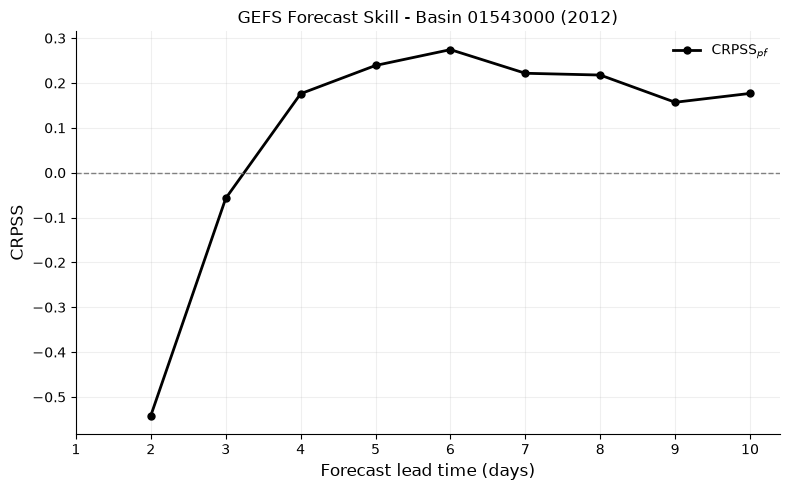


Saved CSV: ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/01543000/CRPSS_pf_01543000_2012.csv
Saved figure: ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/01543000/CRPSS_pf_01543000_2012.png


In [15]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# STEP 1: SETTINGS
# ============================================================

BASIN_ID = "01543000"
YEAR = 2012

N_ENSEMBLES = 5
N_LEADS = 10

# GEFS time coordinate starts on initialization day:
# lead 1 = initialization date
# lead 2 = initialization date + 1 day
# ...
# lead 10 = initialization date + 9 days
LEAD1_OFFSET = 0

SAVE_DIR = os.path.join(
    config["sim_dir"],
    "GEFS_1year_forecasts",
    BASIN_ID
)

# ============================================================
# STEP 2: LOAD SAVED GEFS FORECASTS FROM NPZ FILES
#
# Each file:
#     forecast_YYYYMMDD.npz
#
# Contains:
#     forecast: (5, 10)
#       5 ensemble members x 10 lead days
#
# After loading:
#     forecasts: (n_init_dates, 10, 5)
# ============================================================

files = sorted(glob.glob(
    os.path.join(SAVE_DIR, "forecast_*.npz")
))

forecasts_list = []
init_dates_list = []

for file in files:

    with np.load(file) as data:
        fc = np.asarray(data["forecast"], dtype=float)
        init_date = pd.Timestamp(
            str(data["init_date"].item())
        ).normalize()

    if init_date.year != YEAR:
        continue

    if fc.shape != (N_ENSEMBLES, N_LEADS):
        raise ValueError(
            f"Unexpected forecast shape {fc.shape}: {file}"
        )

    # Convert (ensemble, lead) -> (lead, ensemble)
    forecasts_list.append(fc.T)
    init_dates_list.append(init_date)

if not forecasts_list:
    raise ValueError(
        f"No forecast files found for basin {BASIN_ID}"
    )

forecasts = np.stack(forecasts_list, axis=0)
init_dates = pd.DatetimeIndex(init_dates_list)

if not init_dates.is_unique:
    raise ValueError("Duplicate initialization dates found")

print("Basin:", BASIN_ID)
print("Number of initialization dates:", len(init_dates))
print("Forecast shape:", forecasts.shape)
print("First date:", init_dates.min())
print("Last date:", init_dates.max())


# ============================================================
# STEP 3: GET CONTINUOUS HBV SIMULATION AS REFERENCE
#
# qsim is the continuous HBV streamflow simulation.
#
# It is NOT the GEFS forecast.
#
# basin_results was calculated in your previous notebook cell.
# Make sure it corresponds to your extended simulation period.
# ============================================================

basin_key = str(int(BASIN_ID))

basin_data = basin_results[basin_key]

qsim = np.asarray(
    basin_data["sim"],
    dtype=float
).reshape(-1)

qsim_dates = pd.DatetimeIndex(
    basin_data["dates"]
).normalize()

if len(qsim) != len(qsim_dates):
    raise ValueError(
        "qsim and qsim_dates have different lengths"
    )

if not qsim_dates.is_unique:
    raise ValueError("Duplicate dates in qsim_dates")

qsim_series = pd.Series(
    qsim,
    index=qsim_dates
)

print("\nReference simulation:")
print("qsim shape:", qsim.shape)
print("Date range:", qsim_dates.min(), "to", qsim_dates.max())


# ============================================================
# STEP 4: MATCH FORECASTS WITH REFERENCE STREAMFLOW
#
# For each initialization date and lead time:
#
#   Forecast: five GEFS-driven HBV predictions
#   Reference: continuous HBV streamflow at valid date
#
# Output:
#   reference.shape = (n_init_dates, 10)
# ============================================================

lead_times = np.arange(1, N_LEADS + 1)

valid_dates = (
    init_dates.values[:, None]
    + np.arange(
        LEAD1_OFFSET,
        LEAD1_OFFSET + N_LEADS
    )[None, :].astype("timedelta64[D]")
)

reference = qsim_series.reindex(
    pd.DatetimeIndex(valid_dates.ravel())
).to_numpy().reshape(valid_dates.shape)

# Persistence forecast:
# Assume discharge remains equal to the initialization-day flow.
initial_flow = qsim_series.reindex(
    init_dates
).to_numpy()

print("\nVerification arrays:")
print("Forecast:", forecasts.shape)
print("Reference:", reference.shape)
print("Initial flow:", initial_flow.shape)


# ============================================================
# STEP 5: COMPUTE CRPS FOR EACH INITIALIZATION AND LEAD
#
# Empirical ensemble CRPS:
#
# CRPS = mean(|ensemble - reference|)
#        - 0.5 * mean(|member_i - member_j|)
#
# Input:
#   forecasts: (n_init_dates, 10, 5)
#   reference: (n_init_dates, 10)
#
# Output:
#   crps_cases: (n_init_dates, 10)
# ============================================================

term1 = np.mean(
    np.abs(
        forecasts - reference[:, :, None]
    ),
    axis=2
)

term2 = 0.5 * np.mean(
    np.abs(
        forecasts[:, :, :, None]
        - forecasts[:, :, None, :]
    ),
    axis=(2, 3)
)

crps_cases = term1 - term2

# Use only cases with complete ensemble and reference data
valid = (
    np.isfinite(forecasts).all(axis=2)
    & np.isfinite(reference)
    & np.isfinite(initial_flow[:, None])
)

crps_cases[~valid] = np.nan


# ============================================================
# STEP 6: COMPUTE PERSISTENCE REFERENCE CRPS
#
# Persistence forecast:
#   Q_persistence(t, lead) = Qsim(initialization date)
#
# Since persistence is deterministic:
#   CRPS_ref = |Qsim(valid date) - Qsim(init date)|
#
# Output:
#   crps_ref_cases: (n_init_dates, 10)
# ============================================================

crps_ref_cases = np.abs(
    reference - initial_flow[:, None]
)

crps_ref_cases[~valid] = np.nan


# ============================================================
# STEP 7: AVERAGE CRPS ACROSS INITIALIZATION DATES
#
# For each lead time:
#
#   CRPS_forecast(lead) = mean across initialization dates
#   CRPS_reference(lead) = mean across initialization dates
#
# Output:
#   10 forecast CRPS values
#   10 reference CRPS values
# ============================================================

n_valid = valid.sum(axis=0)

if np.any(n_valid == 0):
    raise ValueError(
        "No valid forecast/reference pairs for lead(s): "
        f"{lead_times[n_valid == 0].tolist()}"
    )

crps_forecast = np.nanmean(
    crps_cases,
    axis=0
)

crps_reference = np.nanmean(
    crps_ref_cases,
    axis=0
)


# ============================================================
# STEP 8: COMPUTE CRPSS FOR EACH LEAD TIME
#
# CRPSS(lead) =
#     1 - CRPS_forecast(lead) / CRPS_reference(lead)
#
# CRPSS > 0 : GEFS forecast better than persistence
# CRPSS = 0 : equal skill
# CRPSS < 0 : GEFS forecast worse than persistence
#
# Output:
#   crpss: (10,)
#
# Note:
#   Lead 1 has zero persistence error when it represents
#   the initialization day, so CRPSS is undefined there.
# ============================================================

crpss = np.full(N_LEADS, np.nan)

valid_ref = (
    np.isfinite(crps_reference)
    & (crps_reference > 0)
)

crpss[valid_ref] = (
    1
    - crps_forecast[valid_ref]
    / crps_reference[valid_ref]
)


# ============================================================
# STEP 9: DISPLAY AND SAVE CRPSS RESULTS
# ============================================================

results_df = pd.DataFrame({
    "lead_time": lead_times,
    "CRPS_forecast": crps_forecast,
    "CRPS_ref_persistence": crps_reference,
    "CRPSS_pf": crpss,
    "n_valid_initializations": n_valid
})

print("\nCRPSS results:")
display(results_df)

csv_path = os.path.join(
    SAVE_DIR,
    f"CRPSS_pf_{BASIN_ID}_{YEAR}.csv"
)

results_df.to_csv(csv_path, index=False)


# ============================================================
# STEP 10: PLOT ONE CRPSS CURVE FOR THIS BASIN
#
# X-axis: forecast lead time (1-10 days)
# Y-axis: CRPSS relative to persistence
#
# One basin -> one CRPSS_pf curve
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    lead_times,
    crpss,
    color="black",
    linewidth=2,
    marker="o",
    markersize=5,
    label=r"CRPSS$_{pf}$"
)

ax.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_xlabel(
    "Forecast lead time (days)",
    fontsize=12
)

ax.set_ylabel(
    "CRPSS",
    fontsize=12
)

ax.set_title(
    f"GEFS Forecast Skill - Basin {BASIN_ID} ({YEAR})",
    fontsize=12
)

ax.set_xticks(lead_times)

ax.legend(frameon=False)
ax.grid(alpha=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

fig_path = os.path.join(
    SAVE_DIR,
    f"CRPSS_pf_{BASIN_ID}_{YEAR}.png"
)

plt.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved CSV:", csv_path)
print("Saved figure:", fig_path)

Basins with saved forecast folders: 1
[1/1] 01543000: 272 initialization dates

CRPSS_pf shape: (1, 10)
CRPSS_ad shape: (1, 10)


/tmp/ipykernel_1995804/3073624454.py:383: RuntimeWarning: Mean of empty slice
  pf_mean = np.nanmean(crpss_pf_all, axis=0)
/u/au/ac/zhennanshi/scratch/conda_envs/dmg312_v100/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


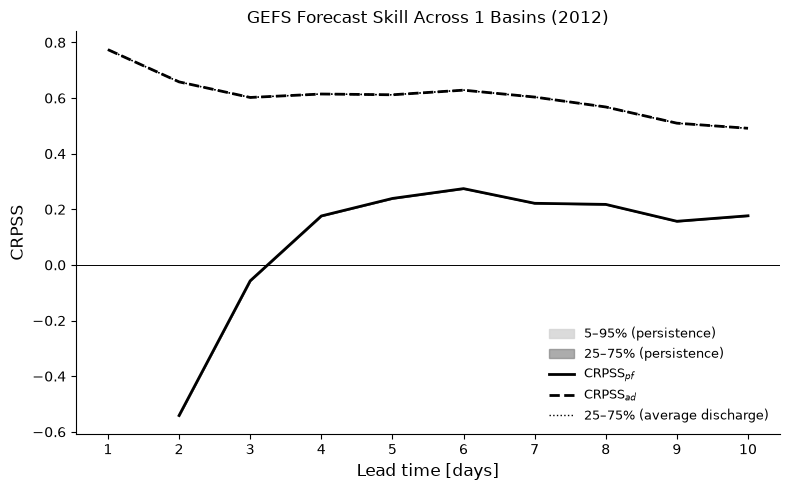


Saved figure: ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/CRPSS_multi_basin/CRPSS_spatial_2012.png
Saved CSV: ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/CRPSS_multi_basin/CRPSS_all_basins_2012.csv
Evaluated basins: 1
Failed basins: 0


In [16]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# STEP 1: SETTINGS
# ============================================================

YEAR = 2012
N_LEADS = 10
N_ENSEMBLES = 5

# GEFS lead 1 corresponds to initialization date.
LEAD1_OFFSET = 0

SAVE_ROOT = os.path.join(
    config["sim_dir"],
    "GEFS_1year_forecasts"
)

OUTPUT_DIR = os.path.join(
    SAVE_ROOT,
    "CRPSS_multi_basin"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Minimum valid forecast cases per lead and basin.
# Increase for publication-quality comparisons.
MIN_VALID_CASES = 30


# ============================================================
# STEP 2: EXACT EMPIRICAL ENSEMBLE CRPS
#
# forecast shape: (n_init_dates, n_leads, n_members)
# reference shape: (n_init_dates, n_leads)
#
# Returns CRPS for each initialization date and lead time.
# ============================================================

def ensemble_crps(forecast, reference):

    term1 = np.mean(
        np.abs(forecast - reference[:, :, None]),
        axis=2
    )

    term2 = 0.5 * np.mean(
        np.abs(
            forecast[:, :, :, None]
            - forecast[:, :, None, :]
        ),
        axis=(2, 3)
    )

    return term1 - term2


# ============================================================
# STEP 3: COMPUTE CRPSS FOR ONE BASIN
#
# For each lead time:
#
# 1. Load all available saved NPZ forecasts.
# 2. Match forecasts with continuous HBV reference.
# 3. Calculate ensemble CRPS.
# 4. Calculate persistence and climatology reference CRPS.
# 5. Average over initialization dates.
# 6. Calculate CRPSS_pf and CRPSS_ad.
#
# Returns two arrays, each with 10 values.
# ============================================================

def compute_basin_crpss(basin_id):

    basin_id = str(basin_id).zfill(8)
    basin_dir = os.path.join(SAVE_ROOT, basin_id)

    files = sorted(glob.glob(
        os.path.join(basin_dir, "forecast_*.npz")
    ))

    if not files:
        raise FileNotFoundError(
            f"No forecast files for basin {basin_id}"
        )

    # ----------------------------------------
    # A. Load GEFS forecasts
    # ----------------------------------------

    forecasts_list = []
    init_dates_list = []

    for file in files:

        with np.load(file) as data:

            fc = np.asarray(
                data["forecast"],
                dtype=float
            )

            init_date = pd.Timestamp(
                str(data["init_date"].item())
            ).normalize()

        if init_date.year != YEAR:
            continue

        if fc.shape != (N_ENSEMBLES, N_LEADS):
            raise ValueError(
                f"Unexpected shape {fc.shape}: {file}"
            )

        forecasts_list.append(fc.T)
        init_dates_list.append(init_date)

    if not forecasts_list:
        raise ValueError(
            f"No forecasts for {basin_id} in {YEAR}"
        )

    forecasts = np.stack(forecasts_list)
    init_dates = pd.DatetimeIndex(init_dates_list)

    if not init_dates.is_unique:
        raise ValueError(
            f"Duplicate initialization dates for {basin_id}"
        )

    # ----------------------------------------
    # B. Load continuous HBV simulation
    # ----------------------------------------

    basin_key = str(int(basin_id))

    if basin_key not in basin_results:
        raise KeyError(
            f"Missing continuous simulation for {basin_id}"
        )

    basin_data = basin_results[basin_key]

    qsim = np.asarray(
        basin_data["sim"],
        dtype=float
    ).reshape(-1)

    qsim_dates = pd.DatetimeIndex(
        basin_data["dates"]
    ).normalize()

    if len(qsim) != len(qsim_dates):
        raise ValueError(
            f"Reference length mismatch: {basin_id}"
        )

    if not qsim_dates.is_unique:
        raise ValueError(
            f"Duplicate reference dates: {basin_id}"
        )

    qsim_series = pd.Series(
        qsim,
        index=qsim_dates
    )

    # ----------------------------------------
    # C. Match forecast valid dates
    # ----------------------------------------

    lead_offsets = np.arange(
        LEAD1_OFFSET,
        LEAD1_OFFSET + N_LEADS
    )

    valid_dates = (
        init_dates.values[:, None]
        + lead_offsets[None, :].astype("timedelta64[D]")
    )

    reference = qsim_series.reindex(
        pd.DatetimeIndex(valid_dates.ravel())
    ).to_numpy().reshape(valid_dates.shape)

    # Persistence: Q at initialization date
    initial_flow = qsim_series.reindex(
        init_dates
    ).to_numpy()

    # ----------------------------------------
    # D. Identify valid forecast cases
    # ----------------------------------------

    valid = (
        np.isfinite(forecasts).all(axis=2)
        & np.isfinite(reference)
        & np.isfinite(initial_flow[:, None])
    )

    n_valid = valid.sum(axis=0)

    # ----------------------------------------
    # E. Compute forecast CRPS
    # ----------------------------------------

    crps_fc_cases = ensemble_crps(
        forecasts, reference
    )

    crps_fc_cases[~valid] = np.nan

    # ----------------------------------------
    # F. Compute persistence reference CRPS
    # ----------------------------------------

    crps_pf_cases = np.abs(
        reference - initial_flow[:, None]
    )

    crps_pf_cases[~valid] = np.nan

    # ----------------------------------------
    # G. Compute climatological reference CRPS
    #
    # Average discharge from continuous HBV simulation.
    # Prefer a separate historical climatology period
    # for a final scientific evaluation.
    # ----------------------------------------

    q_mean = np.nanmean(qsim)

    crps_ad_cases = np.abs(
        reference - q_mean
    )

    crps_ad_cases[~valid] = np.nan

    # ----------------------------------------
    # H. Average CRPS across initialization dates
    # ----------------------------------------

    crps_fc = np.nanmean(
        crps_fc_cases, axis=0
    )

    crps_pf = np.nanmean(
        crps_pf_cases, axis=0
    )

    crps_ad = np.nanmean(
        crps_ad_cases, axis=0
    )

    # ----------------------------------------
    # I. Calculate CRPSS for each lead
    # ----------------------------------------

    crpss_pf = np.full(N_LEADS, np.nan)
    crpss_ad = np.full(N_LEADS, np.nan)

    valid_pf = (
        (n_valid >= MIN_VALID_CASES)
        & np.isfinite(crps_pf)
        & (crps_pf > 0)
    )

    valid_ad = (
        (n_valid >= MIN_VALID_CASES)
        & np.isfinite(crps_ad)
        & (crps_ad > 0)
    )

    crpss_pf[valid_pf] = (
        1 - crps_fc[valid_pf] / crps_pf[valid_pf]
    )

    crpss_ad[valid_ad] = (
        1 - crps_fc[valid_ad] / crps_ad[valid_ad]
    )

    return {
        "basin_id": basin_id,
        "CRPSS_pf": crpss_pf,
        "CRPSS_ad": crpss_ad,
        "CRPS_forecast": crps_fc,
        "n_valid": n_valid,
        "n_init_dates": len(init_dates)
    }


# ============================================================
# STEP 4: FIND ALL BASINS WITH SAVED NPZ FORECASTS
#
# Only basins with forecast files AND continuous reference
# simulations can be evaluated.
# ============================================================

basin_ids = sorted([
    name for name in os.listdir(SAVE_ROOT)
    if (
        os.path.isdir(os.path.join(SAVE_ROOT, name))
        and name.isdigit()
        and len(name) == 8
    )
])

print("Basins with saved forecast folders:", len(basin_ids))


# ============================================================
# STEP 5: CALCULATE CRPSS FOR ALL BASINS
#
# Output:
#   CRPSS_pf_all: (n_basins, 10)
#   CRPSS_ad_all: (n_basins, 10)
# ============================================================

basin_results_crpss = []
failed_basins = []

for i, basin_id in enumerate(basin_ids):

    try:
        result = compute_basin_crpss(basin_id)

        basin_results_crpss.append(result)

        print(
            f"[{i+1}/{len(basin_ids)}] "
            f"{basin_id}: "
            f"{result['n_init_dates']} initialization dates"
        )

    except Exception as e:

        failed_basins.append({
            "basin_id": basin_id,
            "error": str(e)
        })

        print(
            f"FAILED {basin_id}: {e}"
        )

if not basin_results_crpss:
    raise RuntimeError(
        "No basins could be evaluated."
    )

crpss_pf_all = np.stack([
    r["CRPSS_pf"]
    for r in basin_results_crpss
])

crpss_ad_all = np.stack([
    r["CRPSS_ad"]
    for r in basin_results_crpss
])

print("\nCRPSS_pf shape:", crpss_pf_all.shape)
print("CRPSS_ad shape:", crpss_ad_all.shape)


# ============================================================
# STEP 6: COMPUTE SPATIAL MEAN AND PERCENTILES
#
# At each lead time:
#
# Mean = average CRPSS across basins
#
# Light gray area = 5th to 95th percentile
# Dark gray area  = 25th to 75th percentile
#
# Percentiles are across BASINS, not initialization dates.
# ============================================================

lead_times = np.arange(1, N_LEADS + 1)

pf_mean = np.nanmean(crpss_pf_all, axis=0)
ad_mean = np.nanmean(crpss_ad_all, axis=0)

pf_p05 = np.nanpercentile(crpss_pf_all, 5, axis=0)
pf_p25 = np.nanpercentile(crpss_pf_all, 25, axis=0)
pf_p75 = np.nanpercentile(crpss_pf_all, 75, axis=0)
pf_p95 = np.nanpercentile(crpss_pf_all, 95, axis=0)

ad_p25 = np.nanpercentile(crpss_ad_all, 25, axis=0)
ad_p75 = np.nanpercentile(crpss_ad_all, 75, axis=0)


# ============================================================
# STEP 7: PLOT MULTI-BASIN CRPSS FIGURE
#
# Solid black: mean CRPSS_pf
# Dashed black: mean CRPSS_ad
# Light gray: 5th-95th percentiles of CRPSS_pf
# Dark gray: 25th-75th percentiles of CRPSS_pf
# Dotted black: 25th-75th percentiles of CRPSS_ad
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))

# Light gray: 5-95% spatial percentile range
ax.fill_between(
    lead_times,
    pf_p05,
    pf_p95,
    color="lightgray",
    alpha=0.8,
    label="5–95% (persistence)"
)

# Dark gray: 25-75% spatial percentile range
ax.fill_between(
    lead_times,
    pf_p25,
    pf_p75,
    color="gray",
    alpha=0.65,
    label="25–75% (persistence)"
)

# Mean persistence skill
ax.plot(
    lead_times,
    pf_mean,
    color="black",
    linewidth=2,
    linestyle="-",
    label=r"CRPSS$_{pf}$"
)

# Mean average-discharge skill
ax.plot(
    lead_times,
    ad_mean,
    color="black",
    linewidth=2,
    linestyle="--",
    label=r"CRPSS$_{ad}$"
)

# 25-75% average-discharge percentiles
ax.plot(
    lead_times,
    ad_p25,
    color="black",
    linewidth=1,
    linestyle=":"
)

ax.plot(
    lead_times,
    ad_p75,
    color="black",
    linewidth=1,
    linestyle=":",
    label="25–75% (average discharge)"
)

ax.axhline(
    0,
    color="black",
    linewidth=0.7
)

ax.set_xlabel("Lead time [days]", fontsize=12)
ax.set_ylabel("CRPSS", fontsize=12)
ax.set_xticks(lead_times)

ax.set_title(
    f"GEFS Forecast Skill Across {len(basin_results_crpss)} Basins ({YEAR})",
    fontsize=12
)

ax.legend(frameon=False, fontsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

fig_path = os.path.join(
    OUTPUT_DIR,
    f"CRPSS_spatial_{YEAR}.png"
)

fig.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# STEP 8: SAVE BASIN-LEVEL CRPSS RESULTS
#
# Save one row per basin and lead time.
# This allows later analysis without recalculating CRPS.
# ============================================================

rows = []

for result in basin_results_crpss:

    for j, lead in enumerate(lead_times):

        rows.append({
            "basin_id": result["basin_id"],
            "lead_time": lead,
            "CRPSS_pf": result["CRPSS_pf"][j],
            "CRPSS_ad": result["CRPSS_ad"][j],
            "CRPS_forecast": result["CRPS_forecast"][j],
            "n_valid": result["n_valid"][j]
        })

results_df = pd.DataFrame(rows)

csv_path = os.path.join(
    OUTPUT_DIR,
    f"CRPSS_all_basins_{YEAR}.csv"
)

results_df.to_csv(csv_path, index=False)

pd.DataFrame(
    failed_basins,
    columns=["basin_id", "error"]
).to_csv(
    os.path.join(OUTPUT_DIR, "failed_basins.csv"),
    index=False
)

print("\nSaved figure:", fig_path)
print("Saved CSV:", csv_path)
print("Evaluated basins:", len(basin_results_crpss))
print("Failed basins:", len(failed_basins))